In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import math
import numpy as np

base = Path("C:/Users/ARNAV TRIPATHI/Desktop/ANCHOLIK-NER/datasets")

barishal = pd.read_csv(base / "Barishal_NER.csv")
chittagong = pd.read_csv(base / "Chittagong_NER.csv")
mymensingh = pd.read_csv(base / "Mymensingh_NER.csv")
noakhali = pd.read_csv(base / "Noakhali_NER.csv")
sylhet = pd.read_csv(base / "Sylhet_NER.csv")

datasets = {
    "Barishal": barishal,
    "Chittagong": chittagong,
    "Mymensingh": mymensingh,
    "Noakhali": noakhali,
    "Sylhet": sylhet
}

In [3]:
barishal.head()

,Sentence #,barishal_word,bio_tag
0,Sentence: 1,আসো,O
1,NaN,কোরোহম,O
2,Sentence: 2,আইজ,O
3,NaN,মোর,O
4,NaN,মনডা,O


C:\Users\ARNAV TRIPATHI\AppData\Local\Temp\ipykernel_17176\1330334442.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


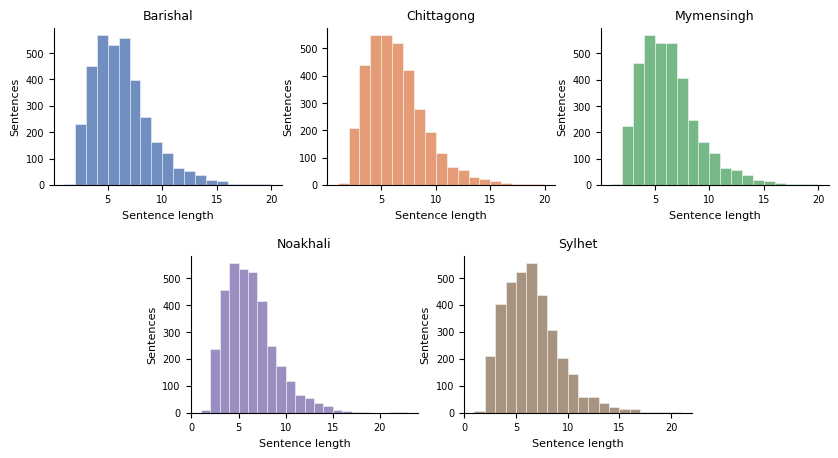

In [17]:
n = len(datasets)

fig = plt.figure(figsize=(10, 5))
gs = fig.add_gridspec(2, 6, hspace=0.45, wspace=0.5)


positions = [
    (0, 0, 2),   
    (0, 2, 2),   
    (0, 4, 2),   
    (1, 1, 2),   
    (1, 3, 2)    
]

colors = ["#4C72B0", "#DD8452", "#55A868", "#8172B2", "#937860"]

for i, (name, df) in enumerate(datasets.items()):

    row, col, width = positions[i]

    ax = fig.add_subplot(
        gs[row, col:col + width]
    )

    sentence_id = df["Sentence #"].ffill()

    sentence_length = sentence_id.value_counts()

    ax.hist(
        sentence_length,
        bins=range(1, sentence_length.max() + 2),
        color=colors[i % len(colors)],
        alpha=0.8,
        edgecolor="white",
        linewidth=0.4
    )

    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Sentence length", fontsize=8)
    ax.set_ylabel("Sentences", fontsize=8)

    ax.tick_params(axis="both", labelsize=7)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

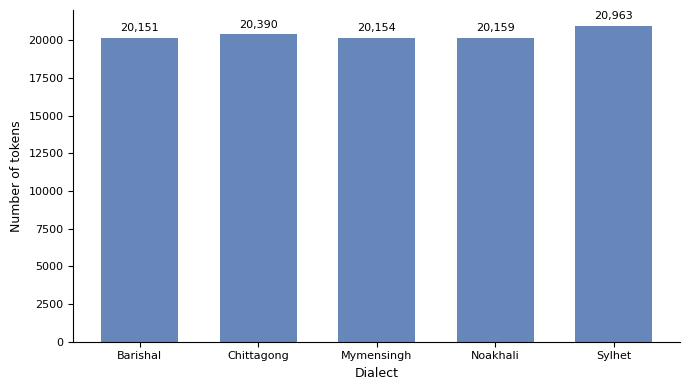

In [18]:
token_counts = [
    len(barishal),
    len(chittagong),
    len(mymensingh),
    len(noakhali),
    len(sylhet)
]

dialects = [
    "Barishal",
    "Chittagong",
    "Mymensingh",
    "Noakhali",
    "Sylhet"
]

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    dialects,
    token_counts,
    color="#4C72B0",
    alpha=0.85,
    width=0.65
)

ax.set_xlabel("Dialect", fontsize=9)
ax.set_ylabel("Number of tokens", fontsize=9)

ax.tick_params(axis="both", labelsize=8)

# Add values above bars
for bar, value in zip(bars, token_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(token_counts) * 0.015,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Clean paper style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

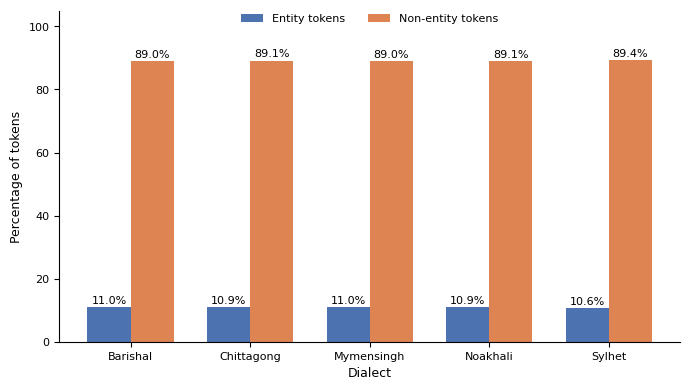

In [20]:
entity_counts = []
non_entity_counts = []

for df in datasets.values():
    entity = (~df["bio_tag"].eq("O")).sum()
    non_entity = df["bio_tag"].eq("O").sum()

    entity_counts.append(entity)
    non_entity_counts.append(non_entity)

# Convert to percentages
entity_pct = [
    e / (e + n) * 100
    for e, n in zip(entity_counts, non_entity_counts)
]

non_entity_pct = [
    n / (e + n) * 100
    for e, n in zip(entity_counts, non_entity_counts)
]

x = range(len(dialects))

fig, ax = plt.subplots(figsize=(7, 4))

width = 0.36

bars1 = ax.bar(
    [i - width / 2 for i in x],
    entity_pct,
    width=width,
    label="Entity tokens",
    color="#4C72B0"
)

bars2 = ax.bar(
    [i + width / 2 for i in x],
    non_entity_pct,
    width=width,
    label="Non-entity tokens",
    color="#DD8452"
)

ax.set_xticks(x)
ax.set_xticklabels(dialects)

ax.set_xlabel("Dialect", fontsize=9)
ax.set_ylabel("Percentage of tokens", fontsize=9)

ax.tick_params(axis="both", labelsize=8)

# Percentage labels
for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{bar.get_height():.1f}%",
            ha="center",
            va="bottom",
            fontsize=8
        )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    fontsize=8,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2
)

ax.set_ylim(0, 105)

plt.tight_layout()
plt.show()

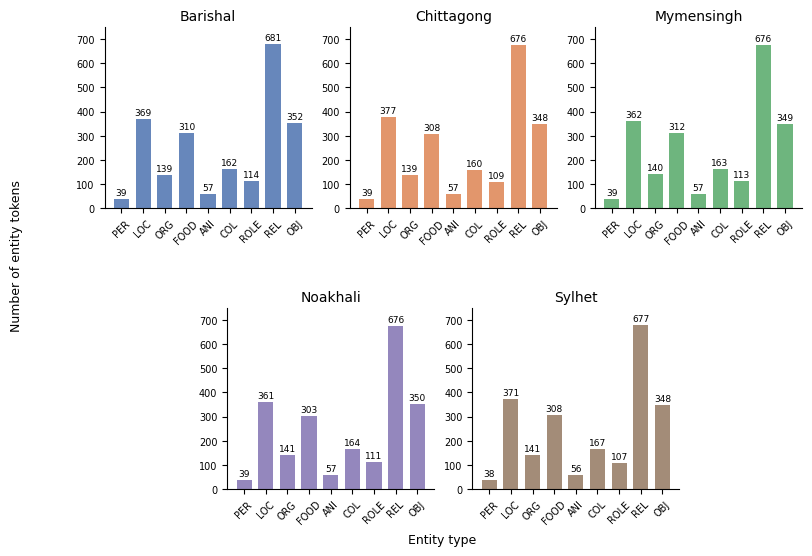

In [27]:
import matplotlib.pyplot as plt
import numpy as np

entity_types = [
    "PER", "LOC", "ORG", "FOOD",
    "ANI", "COL", "ROLE", "REL", "OBJ"
]

counts = {}

for name, df in datasets.items():
    counts[name] = []

    for entity in entity_types:
        count = df["bio_tag"].str.endswith("-" + entity).sum()
        counts[name].append(count)

fig = plt.figure(figsize=(9, 6))

gs = fig.add_gridspec(
    2, 6,
    hspace=0.55,
    wspace=0.45
)

# Positions: 3 top, 2 centred bottom
positions = [
    (0, 0, 2),   # Barishal
    (0, 2, 2),   # Chittagong
    (0, 4, 2),   # Mymensingh
    (1, 1, 2),   # Noakhali
    (1, 3, 2)    # Sylhet
]

colors = [
    "#4C72B0",
    "#DD8452",
    "#55A868",
    "#8172B2",
    "#937860"
]

for i, (name, (row, col, span)) in enumerate(
    zip(dialects, positions)
):

    ax = fig.add_subplot(
        gs[row, col:col + span]
    )

    bars = ax.bar(
        entity_types,
        counts[name],
        color=colors[i],
        alpha=0.85,
        width=0.7
    )

    ax.set_title(name, fontsize=10, pad=5)

    ax.tick_params(
        axis="x",
        labelrotation=45,
        labelsize=7
    )

    ax.tick_params(
        axis="y",
        labelsize=7
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Values above bars
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 8,
            f"{int(bar.get_height())}",
            ha="center",
            va="bottom",
            fontsize=6.5
        )

    ax.set_ylim(0, 750)

# Shared labels
fig.text(
    0.5, 0.02,
    "Entity type",
    ha="center",
    fontsize=9
)

fig.text(
    0.02, 0.5,
    "Number of entity tokens",
    va="center",
    rotation="vertical",
    fontsize=9
)

plt.show()

## Appendix Plots 

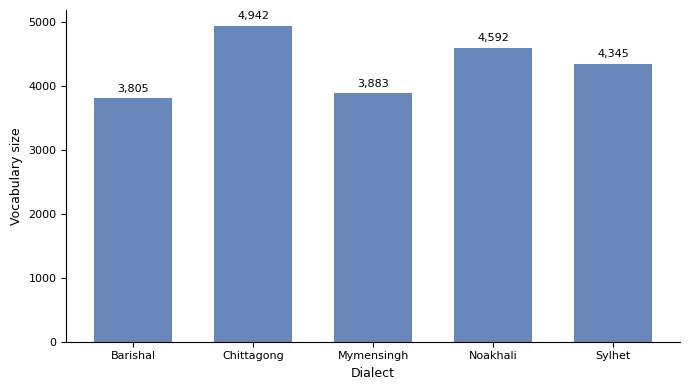

In [28]:
vocabulary_sizes = []

for name, df in datasets.items():

    # Find the word column automatically
    word_column = [
        col for col in df.columns
        if col.endswith("_word")
    ][0]

    vocabulary_sizes.append(
        df[word_column].nunique()
    )

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    dialects,
    vocabulary_sizes,
    color="#4C72B0",
    alpha=0.85,
    width=0.65
)

ax.set_xlabel("Dialect", fontsize=9)
ax.set_ylabel("Vocabulary size", fontsize=9)

ax.tick_params(axis="both", labelsize=8)

# Values above bars
for bar, value in zip(bars, vocabulary_sizes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(vocabulary_sizes) * 0.015,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Clean conference-paper style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [35]:
rows = []

for name, df in datasets.items():

    word_column = [c for c in df.columns if c.endswith("_word")][0]

    rows.append({
        "Dialect": name,
        "Rows / Tokens": len(df),
        "Sentences": df["Sentence #"].nunique(),
        "Unique Tokens": df[word_column].nunique(),
        "Missing Values": df.isna().sum().sum()
    })

dataset_structure = pd.DataFrame(rows)

dataset_structure

,Dialect,Rows / Tokens,Sentences,Unique Tokens,Missing Values
0,Barishal,20151,3481,3805,16670
1,Chittagong,20390,3481,4942,16909
2,Mymensingh,20154,3481,3883,16673
3,Noakhali,20159,3481,4592,16678
4,Sylhet,20963,3481,4345,17482


In [42]:
rows = []

for name, df in datasets.items():

    sentence_id = df["Sentence #"].ffill()

    sentence_lengths = sentence_id.groupby(sentence_id).size()

    rows.append({
        "Dialect": name,
        "Min": sentence_lengths.min(),
        "Q1": sentence_lengths.quantile(0.25),
        "Mean": round(sentence_lengths.mean(), 2),
        "Median": sentence_lengths.median(),
        "Q3": sentence_lengths.quantile(0.75),
        "Max": sentence_lengths.max()
    })

sentence_length_table = pd.DataFrame(rows)

sentence_length_table

,Dialect,Min,Q1,Mean,Median,Q3,Max
0,Barishal,1,4.0,5.79,5.0,7.0,19
1,Chittagong,1,4.0,5.86,5.0,7.0,19
2,Mymensingh,1,4.0,5.79,5.0,7.0,19
3,Noakhali,1,4.0,5.79,5.0,7.0,22
4,Sylhet,1,4.0,6.02,6.0,7.0,20


In [38]:
vocab = {}

for name, df in datasets.items():

    word_column = [c for c in df.columns if c.endswith("_word")][0]

    vocab[name] = set(df[word_column])

vocab_sizes = pd.DataFrame({
    "Dialect": vocab.keys(),
    "Vocabulary Size": [len(v) for v in vocab.values()]
})

vocab_sizes

,Dialect,Vocabulary Size
0,Barishal,3805
1,Chittagong,4942
2,Mymensingh,3883
3,Noakhali,4592
4,Sylhet,4345


In [39]:
dialects = list(vocab.keys())

overlap = pd.DataFrame(
    index=dialects,
    columns=dialects
)

for d1 in dialects:

    for d2 in dialects:

        common_words = vocab[d1] & vocab[d2]
        all_words = vocab[d1] | vocab[d2]

        overlap.loc[d1, d2] = round(
            len(common_words) / len(all_words),
            4
        )

overlap

,Barishal,Chittagong,Mymensingh,Noakhali,Sylhet
Barishal,1.0,0.1124,0.2995,0.2171,0.1841
Chittagong,0.1124,1.0,0.1477,0.1554,0.1401
Mymensingh,0.2995,0.1477,1.0,0.2874,0.2386
Noakhali,0.2171,0.1554,0.2874,1.0,0.1945
Sylhet,0.1841,0.1401,0.2386,0.1945,1.0


In [40]:
entity_types = [
    "PER", "LOC", "ORG", "FOOD",
    "ANI", "COL", "ROLE", "REL", "OBJ"
]

rows = []

for name, df in datasets.items():

    row = {"Dialect": name}

    for entity in entity_types:

        count = df["bio_tag"].str.endswith(
            "-" + entity
        ).sum()

        row[entity] = count

    rows.append(row)

entity_distribution = pd.DataFrame(rows)

entity_distribution

,Dialect,PER,LOC,ORG,FOOD,ANI,COL,ROLE,REL,OBJ
0,Barishal,39,369,139,310,57,162,114,681,352
1,Chittagong,39,377,139,308,57,160,109,676,348
2,Mymensingh,39,362,140,312,57,163,113,676,349
3,Noakhali,39,361,141,303,57,164,111,676,350
4,Sylhet,38,371,141,308,56,167,107,677,348


In [41]:
rows = []

for name, df in datasets.items():

    entity = (~df["bio_tag"].eq("O")).sum()
    non_entity = df["bio_tag"].eq("O").sum()

    rows.append({
        "Dialect": name,
        "Entity Tokens": entity,
        "Non-Entity Tokens": non_entity,
        "Entity %": round(entity / len(df) * 100, 2),
        "Non-Entity %": round(non_entity / len(df) * 100, 2)
    })

entity_balance = pd.DataFrame(rows)

entity_balance

,Dialect,Entity Tokens,Non-Entity Tokens,Entity %,Non-Entity %
0,Barishal,2223,17928,11.03,88.97
1,Chittagong,2213,18177,10.85,89.15
2,Mymensingh,2211,17943,10.97,89.03
3,Noakhali,2202,17957,10.92,89.08
4,Sylhet,2213,18750,10.56,89.44


In [43]:
# Find invalid BIO sequences

for name, df in datasets.items():

    # Fill sentence IDs down
    sentence_id = df["Sentence #"].ffill()

    previous_tag = "O"

    for i, tag in enumerate(df["bio_tag"]):

        tag = str(tag).strip()

        # B- tags are always valid starts
        if tag.startswith("B-"):
            previous_tag = tag

        # O is always valid
        elif tag == "O":
            previous_tag = "O"

        # I- tag must follow the same entity type
        elif tag.startswith("I-"):

            entity_type = tag[2:]

            if previous_tag != "B-" + entity_type and previous_tag != tag:

                print(
                    name,
                    "| Sentence:",
                    sentence_id.iloc[i],
                    "| Row:",
                    i,
                    "| Previous:",
                    previous_tag,
                    "| Current:",
                    tag
                )

            previous_tag = tag

Chittagong | Sentence: Sentence: 47 | Row: 299 | Previous: O | Current: I-LOC
Chittagong | Sentence: Sentence: 48 | Row: 306 | Previous: O | Current: I-LOC
Chittagong | Sentence: Sentence: 92 | Row: 592 | Previous: B-COL | Current: I-OBJ
Chittagong | Sentence: Sentence: 362 | Row: 2827 | Previous: O | Current: I-OBJ
Chittagong | Sentence: Sentence: 391 | Row: 3078 | Previous: O | Current: I-LOC
Chittagong | Sentence: Sentence: 476 | Row: 3630 | Previous: O | Current: I-LOC
Chittagong | Sentence: Sentence: 1506 | Row: 10272 | Previous: O | Current: I-LOC
Mymensingh | Sentence: Sentence: 270 | Row: 2087 | Previous: B-REL | Current: I-LOC
Noakhali | Sentence: Sentence: 270 | Row: 2101 | Previous: B-REL | Current: I-LOC
Noakhali | Sentence: Sentence: 1828 | Row: 12188 | Previous: O | Current: I-FOOD
Noakhali | Sentence: Sentence: 1864 | Row: 12441 | Previous: O | Current: I-OBJ
Noakhali | Sentence: Sentence: 2489 | Row: 16541 | Previous: B-ORG | Current: I-REL
Sylhet | Sentence: Sentence: 

In [45]:
# Show the complete sentence for every invalid BIO transition

for name, df in datasets.items():

    sentence_id = df["Sentence #"].ffill()

    previous_tag = "O"

    for i, tag in enumerate(df["bio_tag"]):

        tag = str(tag).strip()

        if tag.startswith("B-"):
            previous_tag = tag

        elif tag == "O":
            previous_tag = "O"

        elif tag.startswith("I-"):

            entity_type = tag[2:]

            if previous_tag != "B-" + entity_type and previous_tag != tag:

                sid = sentence_id.iloc[i]

                sentence = df[sentence_id == sid]

                print("\n", name, "|", sid)
                for _, row in sentence.iterrows():
                    print(
                        f"{row.iloc[1]} / {row['bio_tag']}",
                        end="    "
                    )

                print()

            previous_tag = tag


 Chittagong | Sentence: 47
ইতে / O    বিদ্যালয় / B-LOC    অর / O    মাডঅত / I-LOC    ফত্তিন / O    ক্রিকেট / O    কেলে / O    

 Chittagong | Sentence: 48
ইবা / O    বিদ্যালয় / B-LOC    অর / O    মাডঅত / I-LOC    মায়া / O    গুরি / O    ফরি / O    গেইয়্যুই / O    

 Chittagong | Sentence: 92
মাইফোয়া / O    ইবা / O    লাল / B-COL    শারি / I-OBJ    ফিন্দি / O    তিয়ায় / O    তাইক্কে / O    

 Chittagong | Sentence: 362
এব্বার / O    দইরলে / O    আত / O    ন / O    চারিবা / O    হনো / O    সময় / O    লেডা / O    মাইফোয়া / O    ওক্কলেরে / O    দেইলে / O    মনো / O    অয় / O    বিটামিন / B-OBJ    অর / O    বতল / I-OBJ    কিনি / O    দি / O    

 Chittagong | Sentence: 391
গুরিচ্চাইন্না / B-LOC    এক্কান / O    গেরামত / I-LOC    ওজ্ঞা / O    মাইফোয়া / O    আচিল / O    

 Chittagong | Sentence: 476
মেগনা / B-LOC    বাংলাদেশঅর / B-LOC    এক্কান / O    ফ্রদান / O    নদি / I-LOC    

 Chittagong | Sentence: 1506
দইন / B-LOC    অর / O    জেলা / I-LOC    হক্সবাজার / I-LOC    

 Mymensingh | Sent

In [46]:
# Count types of BIO anomalies

anomaly_counts = {
    "I- tag after O": 0,
    "I- tag after different entity": 0
}

for name, df in datasets.items():

    previous_tag = "O"

    for tag in df["bio_tag"]:

        tag = str(tag).strip()

        if tag.startswith("B-"):
            previous_tag = tag

        elif tag == "O":
            previous_tag = "O"

        elif tag.startswith("I-"):

            entity_type = tag[2:]

            if previous_tag == "O":
                anomaly_counts["I- tag after O"] += 1

            elif previous_tag != "B-" + entity_type and previous_tag != tag:
                anomaly_counts["I- tag after different entity"] += 1

            previous_tag = tag

print(anomaly_counts)

{'I- tag after O': 26, 'I- tag after different entity': 5}


In [49]:
files = {
    "Barishal": base / "Barishal_NER.csv",
    "Chittagong": base / "Chittagong_NER.csv",
    "Mymensingh": base / "Mymensingh_NER.csv",
    "Noakhali": base / "Noakhali_NER.csv",
    "Sylhet": base / "Sylhet_NER.csv"
}

audit = []

for dialect, file in files.items():

    df = pd.read_csv(file)

    # Fill sentence IDs down
    sentence_ids = (
        df["Sentence #"]
        .ffill()
        .astype(str)
        .str.extract(r"(\d+)")[0]
        .astype(int)
    )

    word_column = [
        c for c in df.columns
        if c.endswith("_word")
    ][0]

    previous_tag = "O"

    for i, tag in enumerate(df["bio_tag"].astype(str).str.strip()):

        if tag.startswith("B-"):
            previous_tag = tag

        elif tag == "O":
            previous_tag = "O"

        elif tag.startswith("I-"):

            entity_type = tag[2:]

            # Check whether I-X follows the correct B-X/I-X
            if previous_tag == "O":
                anomaly = "I-tag after O"

            elif previous_tag != "B-" + entity_type and previous_tag != tag:
                anomaly = "I-tag after different entity type"

            else:
                previous_tag = tag
                continue

            # Get complete sentence
            sid = sentence_ids.iloc[i]
            sentence = df[sentence_ids == sid]

            tokens = sentence[word_column].astype(str).tolist()
            tags = sentence["bio_tag"].astype(str).str.strip().tolist()

            audit.append({
                "Dialect": dialect,
                "Sentence ID": sid,
                "Row": i,
                "Previous Tag": previous_tag,
                "Invalid Tag": tag,
                "Anomaly Type": anomaly,
                "Sentence": " ".join(tokens),
                "BIO Sequence": " ".join(
                    f"{word}/{bio}"
                    for word, bio in zip(tokens, tags)
                ),
                "Decision": "",
                "Correction": "",
                "Reason": ""
            })

            previous_tag = tag

audit_table = pd.DataFrame(audit)

print("Total anomalies:", len(audit_table))

audit_table

Total anomalies: 31


,Dialect,Sentence ID,Row,Previous Tag,Invalid Tag,Anomaly Type,Sentence,BIO Sequence,Decision,Correction,Reason
0,Chittagong,47,299,O,I-LOC,I-tag after O,ইতে বিদ্যালয় অর মাডঅত ফত্তিন ক্রিকেট কেলে,ইতে/O বিদ্যালয়/B-LOC অর/O মাডঅত/I-LOC ফত্তিন/O...,,,
1,Chittagong,48,306,O,I-LOC,I-tag after O,ইবা বিদ্যালয় অর মাডঅত মায়া গুরি ফরি গেইয়্যুই,ইবা/O বিদ্যালয়/B-LOC অর/O মাডঅত/I-LOC মায়া/O গ...,,,
2,Chittagong,92,592,B-COL,I-OBJ,I-tag after different entity type,মাইফোয়া ইবা লাল শারি ফিন্দি তিয়ায় তাইক্কে,মাইফোয়া/O ইবা/O লাল/B-COL শারি/I-OBJ ফিন্দি/O ...,,,
3,Chittagong,362,2827,O,I-OBJ,I-tag after O,এব্বার দইরলে আত ন চারিবা হনো সময় লেডা মাইফোয়া ...,এব্বার/O দইরলে/O আত/O ন/O চারিবা/O হনো/O সময়/O...,,,
4,Chittagong,391,3078,O,I-LOC,I-tag after O,গুরিচ্চাইন্না এক্কান গেরামত ওজ্ঞা মাইফোয়া আচিল,গুরিচ্চাইন্না/B-LOC এক্কান/O গেরামত/I-LOC ওজ্ঞ...,,,
5,Chittagong,476,3630,O,I-LOC,I-tag after O,মেগনা বাংলাদেশঅর এক্কান ফ্রদান নদি,মেগনা/B-LOC বাংলাদেশঅর/B-LOC এক্কান/O ফ্রদান/O...,,,
6,Chittagong,1506,10272,O,I-LOC,I-tag after O,দইন অর জেলা হক্সবাজার,দইন/B-LOC অর/O জেলা/I-LOC হক্সবাজার/I-LOC,,,
7,Mymensingh,270,2087,B-REL,I-LOC,I-tag after different entity type,আমি আমার ছোডো বাচ্চারে লইয়া বাপের বাড়িত যাই,আমি/O আমার/O ছোডো/B-REL বাচ্চারে/I-REL লইয়া/O ...,,,
8,Noakhali,270,2101,B-REL,I-LOC,I-tag after different entity type,আই আর ছোট বাচ্চাগারে লই বাবার বাইত যাই,আই/O আর/O ছোট/B-REL বাচ্চাগারে/I-REL লই/O বাবা...,,,
9,Noakhali,1828,12188,O,I-FOOD,I-tag after O,বুইজা নাইলকেল এর হানি হছন্দ করে,বুইজা/B-REL নাইলকেল/B-FOOD এর/O হানি/I-FOOD হছ...,,,


In [50]:
audit_table.to_csv(
    base / "BIO_annotation_audit.csv",
    index=False
)

print("Audit table saved.")

Audit table saved.
